# Model comparison

Compares the geoai models and simple CVA to the torchgeo models. 
The models were already tested in change_detection_mini.ipynb. Here they are run on the test area and model performance is evaluated systematically

In [1]:
# Setup

from pathlib import Path

PROJECT_DIR = Path.cwd()
PROJECT_DIR = PROJECT_DIR.parent

DATA_DIR = PROJECT_DIR / "data"
RAW_DATA_DIR = DATA_DIR / "raw"
PROCESSED_DATA_DIR = DATA_DIR / "processed"
RESULTS_DIR = PROJECT_DIR / "results"
FIGURES_DIR = RESULTS_DIR / "figures"

STUDY_AREA = "Nepal, Syabru Besi"
TARGET_CRS = "EPSG:32645"  # UTM zone 45N

print(f"Project directory: {PROJECT_DIR}")
print(f"Study area: {STUDY_AREA}")
print(f"Target CRS: {TARGET_CRS}")

Project directory: c:\Users\herol\Documents\sds320_project
Study area: Nepal, Syabru Besi
Target CRS: EPSG:32645


In [2]:
import matplotlib.pyplot as plt
from pathlib import Path
import rasterio

import numpy as np
from sklearn.metrics import confusion_matrix, precision_score, recall_score

In [4]:
import geoai

from geoai.change_detection import (
    ChangeStarDetection,
    changestar_detect,
    list_changestar_models,
)

models = list_changestar_models()
for short_name, full_name in models.items():
    print(f"{short_name:30s} -> {full_name}")

INFO:numexpr.utils:NumExpr defaulting to 8 threads.
c:\Users\herol\miniconda3_v2\envs\sds320_v8\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
c:\Users\herol\miniconda3_v2\envs\sds320_v8\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
c:\Users\herol\miniconda3_v2\envs\sds320_v8\Lib\site-packages\torchange\models\changestar_1xd.py:81: UserWarning: CUDA is not available or torch_xla is imported. Disabling autocast.
  @torch.amp.autocast('cuda', dtype=torch.float32)
c:\Users\herol\miniconda3_v2\envs\sds320_v8\Lib\site-packages\torchange\models\changestar_1xd.py:235: UserWarning: CUDA is not available or torch_xla is imported. Disabling autocast.
  @torch.amp.autocast('cuda', dtype=torch.float32)


s0_s1c1_vitb                   -> s0_init_s1c1_changestar_vitb_1x256
s0_s1c5_vitb                   -> s0_init_s1c5_changestar_vitb_1x256
s0_s9c1_vitb                   -> s0_init_s9c1_changestar_vitb_1x256
s0_xview2_s1c5_vitb            -> s0_init_xView2_ft_s1c5_changestar_vitb_1x256
s1_s1c1_vitb                   -> s1_init_s1c1_changestar_vitb_1x256
s1_s1c1_vitl                   -> s1_init_s1c1_changestar_vitl_1x256
s9_s9c1_vitb                   -> s9_init_s9c1_changestar_vitb_1x256


In [3]:
#create RGB images from Sentinel-2 bands for geoai model input
base = PROCESSED_DATA_DIR / "s2_sub_test"
folders = ["t1", "t2"]
bands = ["B04.tif", "B03.tif", "B02.tif"]  # R, G, B

for folder_name in folders:
    folder = base / folder_name
    out_path = folder / f"RGB_{folder_name}.tif"

    if out_path.exists():  #check if the file already exists, if yes, skip downloading
        print(f"File {out_path} already exists. Skipping RGB tif creation.")
        continue

    with rasterio.open(folder / bands[0]) as ref:
        profile = ref.profile.copy()
    profile.update(count=3)

    with rasterio.open(out_path, "w", **profile) as dst:
        for i, name in enumerate(bands, start=1):
            with rasterio.open(folder / name) as src:
                dst.write(src.read(1), i)
                dst.set_band_description(i, Path(name).stem)

    print(f"Saved {out_path}")

path_before = PROCESSED_DATA_DIR / "s2_sub_test" / "t1" / "RGB_t1.tif"
path_after = PROCESSED_DATA_DIR / "s2_sub_test" / "t2" / "RGB_t2.tif"

File c:\Users\herol\Documents\sds320_project\data\processed\s2_sub_test\t1\RGB_t1.tif already exists. Skipping RGB tif creation.
File c:\Users\herol\Documents\sds320_project\data\processed\s2_sub_test\t2\RGB_t2.tif already exists. Skipping RGB tif creation.


## ChangeStar s9

In [22]:
MODEL_RESULTS_DIR = RESULTS_DIR / "model_comparison" / "s9"
MODEL_RESULTS_DIR.mkdir(parents=True, exist_ok=True)

detector_s9 = ChangeStarDetection(model_name="s9_s9c1_vitb")
result_s9 = detector_s9.predict(    
    path_before,
    path_after,
    output_change=str(MODEL_RESULTS_DIR / "change_map_s9.tif"),
    output_t1_semantic=str(MODEL_RESULTS_DIR / "t1_semantic_s9.tif"),
    output_t2_semantic=str(MODEL_RESULTS_DIR / "t2_semantic_s9.tif"),
    output_vector=str(MODEL_RESULTS_DIR / "changes_s9.gpkg"),
    tile_size=256, #fix tile size to avoid issues due to non-square input tiff files
    overlap=64
)

INFO:httpx2:HTTP Request: HEAD https://huggingface.co/EVER-Z/Changen2-ChangeStar1x256/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
INFO:httpx2:HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/EVER-Z/Changen2-ChangeStar1x256/a51540d0abaca8f2b96ccd97139ccd4cfe55bd67/config.json?%2FEVER-Z%2FChangen2-ChangeStar1x256%2Fresolve%2Fmain%2Fconfig.json=&etag=%227602b10a701ea8ed91992247f5249ded5c2775fe%22 "HTTP/1.1 200 OK"
INFO:httpx2:HTTP Request: HEAD https://huggingface.co/EVER-Z/Changen2-ChangeStar1x256/resolve/main/s9c1_cstar_vitb_1x256.pth "HTTP/1.1 302 Found"
2026-11-19 12:15:29, INFO:EVER:Load Changen2 pre-trained weight from EVER-Z/Changen2-ChangeStar1x256/s9c1_cstar_vitb_1x256.pth
2026-11-19 12:15:29, INFO:EVER:architecture: changestar_1x256 | backbone: vitb | modeling type: s9c1 | pre-trained data: Changen2-S9-27k | finetuned on: None
INFO:pyogrio._io:Created 14 records


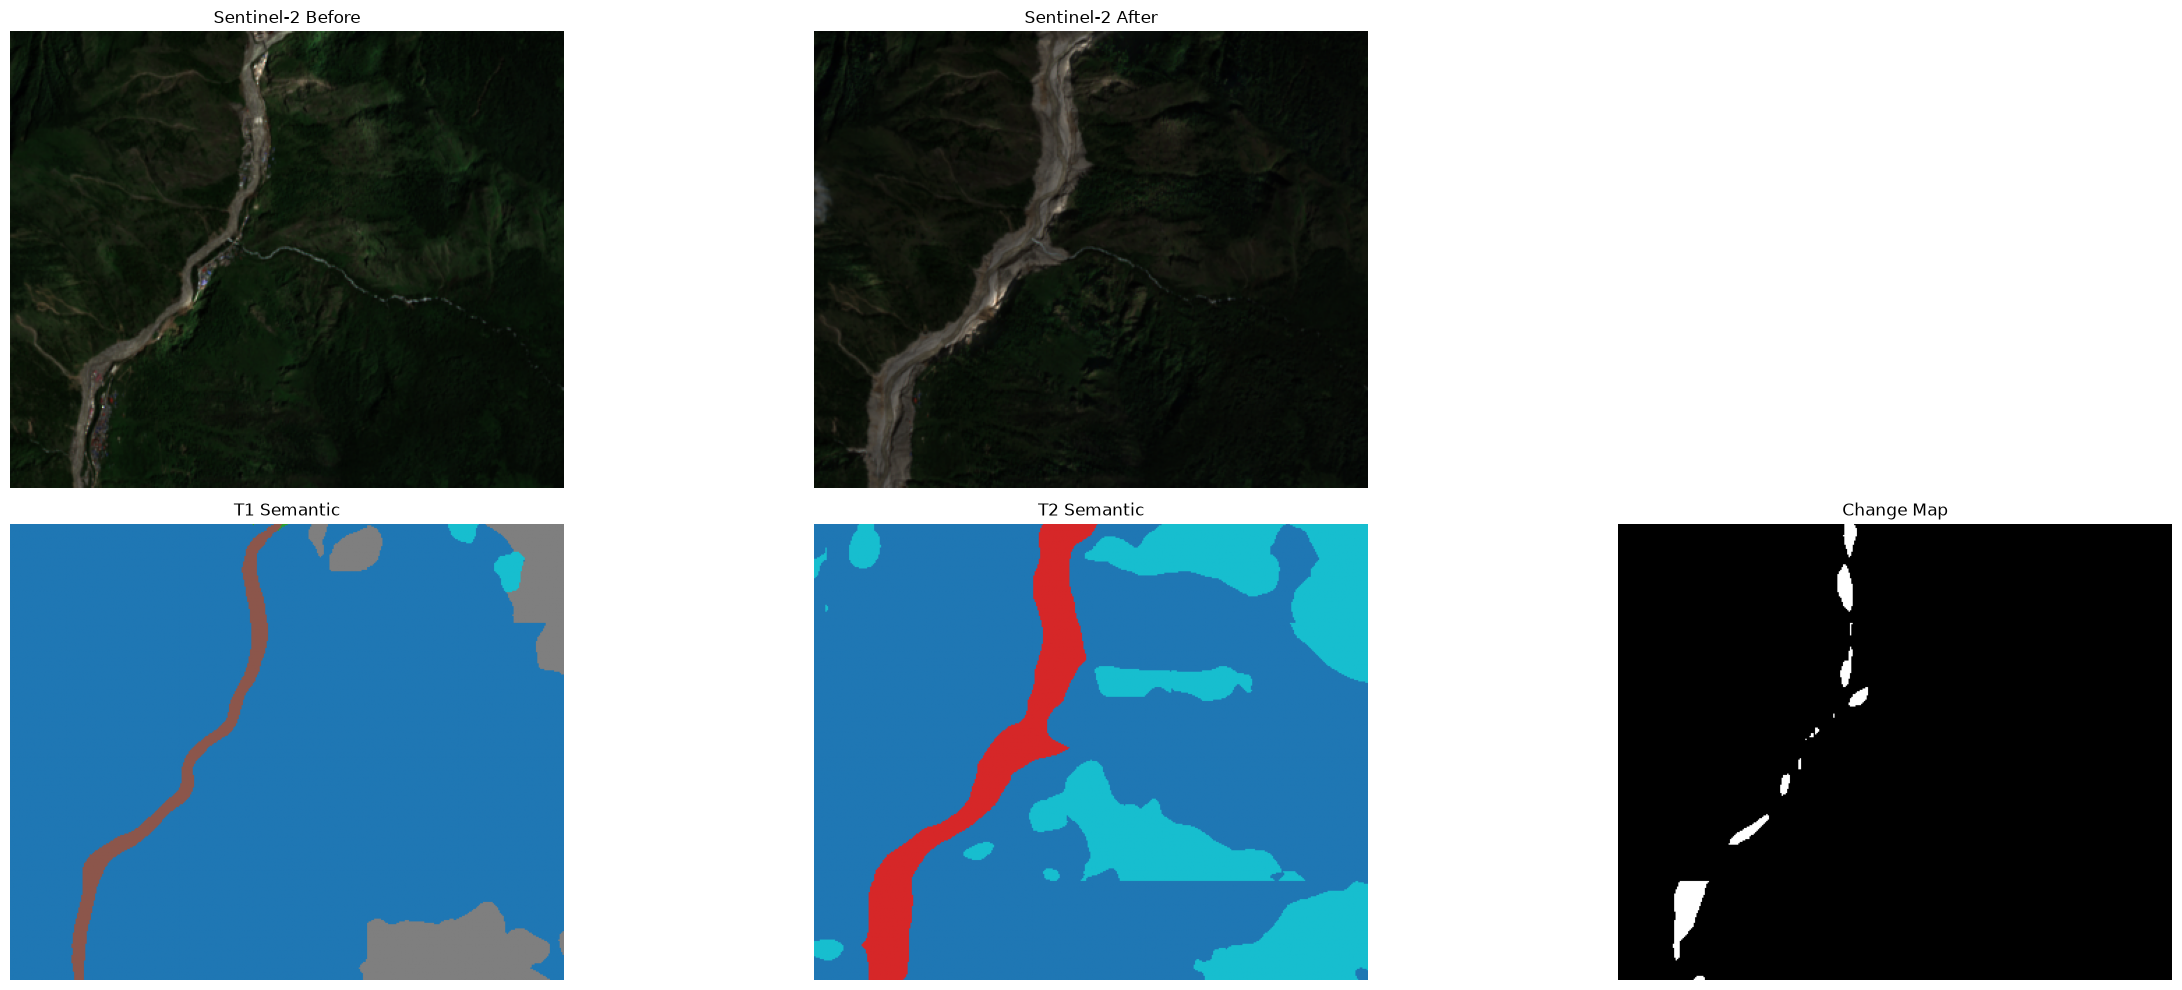

In [23]:
fig = detector_s9.visualize(
    path_before,
    path_after,
    result=result_s9,
    figsize=(25, 10),
    title1="Sentinel-2 Before",
    title2="Sentinel-2 After",
)
plt.show()

In [24]:
gt_path = PROCESSED_DATA_DIR / "s2_sub_test" / "mask" / "scene001.tif"
pred_path = MODEL_RESULTS_DIR / "change_map_s9.tif"

with rasterio.open(gt_path) as src:
    gt = src.read(1)

with rasterio.open(pred_path) as src:
    pred = src.read(1)

if gt.shape != pred.shape:
    raise ValueError(f"Shape mismatch: GT {gt.shape} vs prediction {pred.shape}")

y_true = gt > 0
y_pred = pred > 0

tp = np.count_nonzero(y_true & y_pred)
fp = np.count_nonzero(~y_true & y_pred)
fn = np.count_nonzero(y_true & ~y_pred)
tn = np.count_nonzero(~y_true & ~y_pred)

precision = tp / (tp + fp) if (tp + fp) else 0.0
recall = tp / (tp + fn) if (tp + fn) else 0.0
iou = tp / (tp + fp + fn) if (tp + fp + fn) else 0.0

print("Confusion matrix (rows = actual, columns = predicted)")
print(f"{'':>18}{'Pred 0':>12}{'Pred 1':>12}")
print(f"{'Actual 0':>18}{tn:>12}{fp:>12}")
print(f"{'Actual 1':>18}{fn:>12}{tp:>12}")
print()
print(f"Precision: {precision:.3f}")
print(f"Recall:    {recall:.3f}")
print(f"IoU:       {iou:.3f}")


Confusion matrix (rows = actual, columns = predicted)
                        Pred 0      Pred 1
          Actual 0      118937           6
          Actual 1        9126        1750

Precision: 0.997
Recall:    0.161
IoU:       0.161


## ChangeStar S0

In [12]:
MODEL_RESULTS_DIR = RESULTS_DIR / "model_comparison" / "s0"
MODEL_RESULTS_DIR.mkdir(parents=True, exist_ok=True)

detector_s0 = ChangeStarDetection(model_name="s0_s9c1_vitb")
result_s0 = detector_s0.predict(    
    path_before,
    path_after,
    output_change=str(MODEL_RESULTS_DIR / "change_map_s0.tif"),
    output_t1_semantic=str(MODEL_RESULTS_DIR / "t1_semantic_s0.tif"),
    output_t2_semantic=str(MODEL_RESULTS_DIR / "t2_semantic_s0.tif"),
    output_vector=str(MODEL_RESULTS_DIR / "changes_s0.gpkg"),
    tile_size=256, #fix tile size to avoid issues due to non-square input tiff files
    overlap=64
)

INFO:httpx2:HTTP Request: HEAD https://huggingface.co/EVER-Z/Changen2-ChangeStar1x256/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
INFO:httpx2:HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/EVER-Z/Changen2-ChangeStar1x256/a51540d0abaca8f2b96ccd97139ccd4cfe55bd67/config.json?%2FEVER-Z%2FChangen2-ChangeStar1x256%2Fresolve%2Fmain%2Fconfig.json=&etag=%227602b10a701ea8ed91992247f5249ded5c2775fe%22 "HTTP/1.1 200 OK"
INFO:httpx2:HTTP Request: HEAD https://huggingface.co/EVER-Z/Changen2-ChangeStar1x256/resolve/main/s0_cstar_vitb_1x256.pth "HTTP/1.1 302 Found"
2026-11-19 12:04:58, INFO:EVER:Load Changen2 pre-trained weight from EVER-Z/Changen2-ChangeStar1x256/s0_cstar_vitb_1x256.pth
2026-11-19 12:04:58, INFO:EVER:architecture: changestar_1x256 | backbone: vitb | modeling type: s9c1 | pre-trained data: Changen2-S0-1.2M | finetuned on: None
INFO:pyogrio._io:Created 23 records


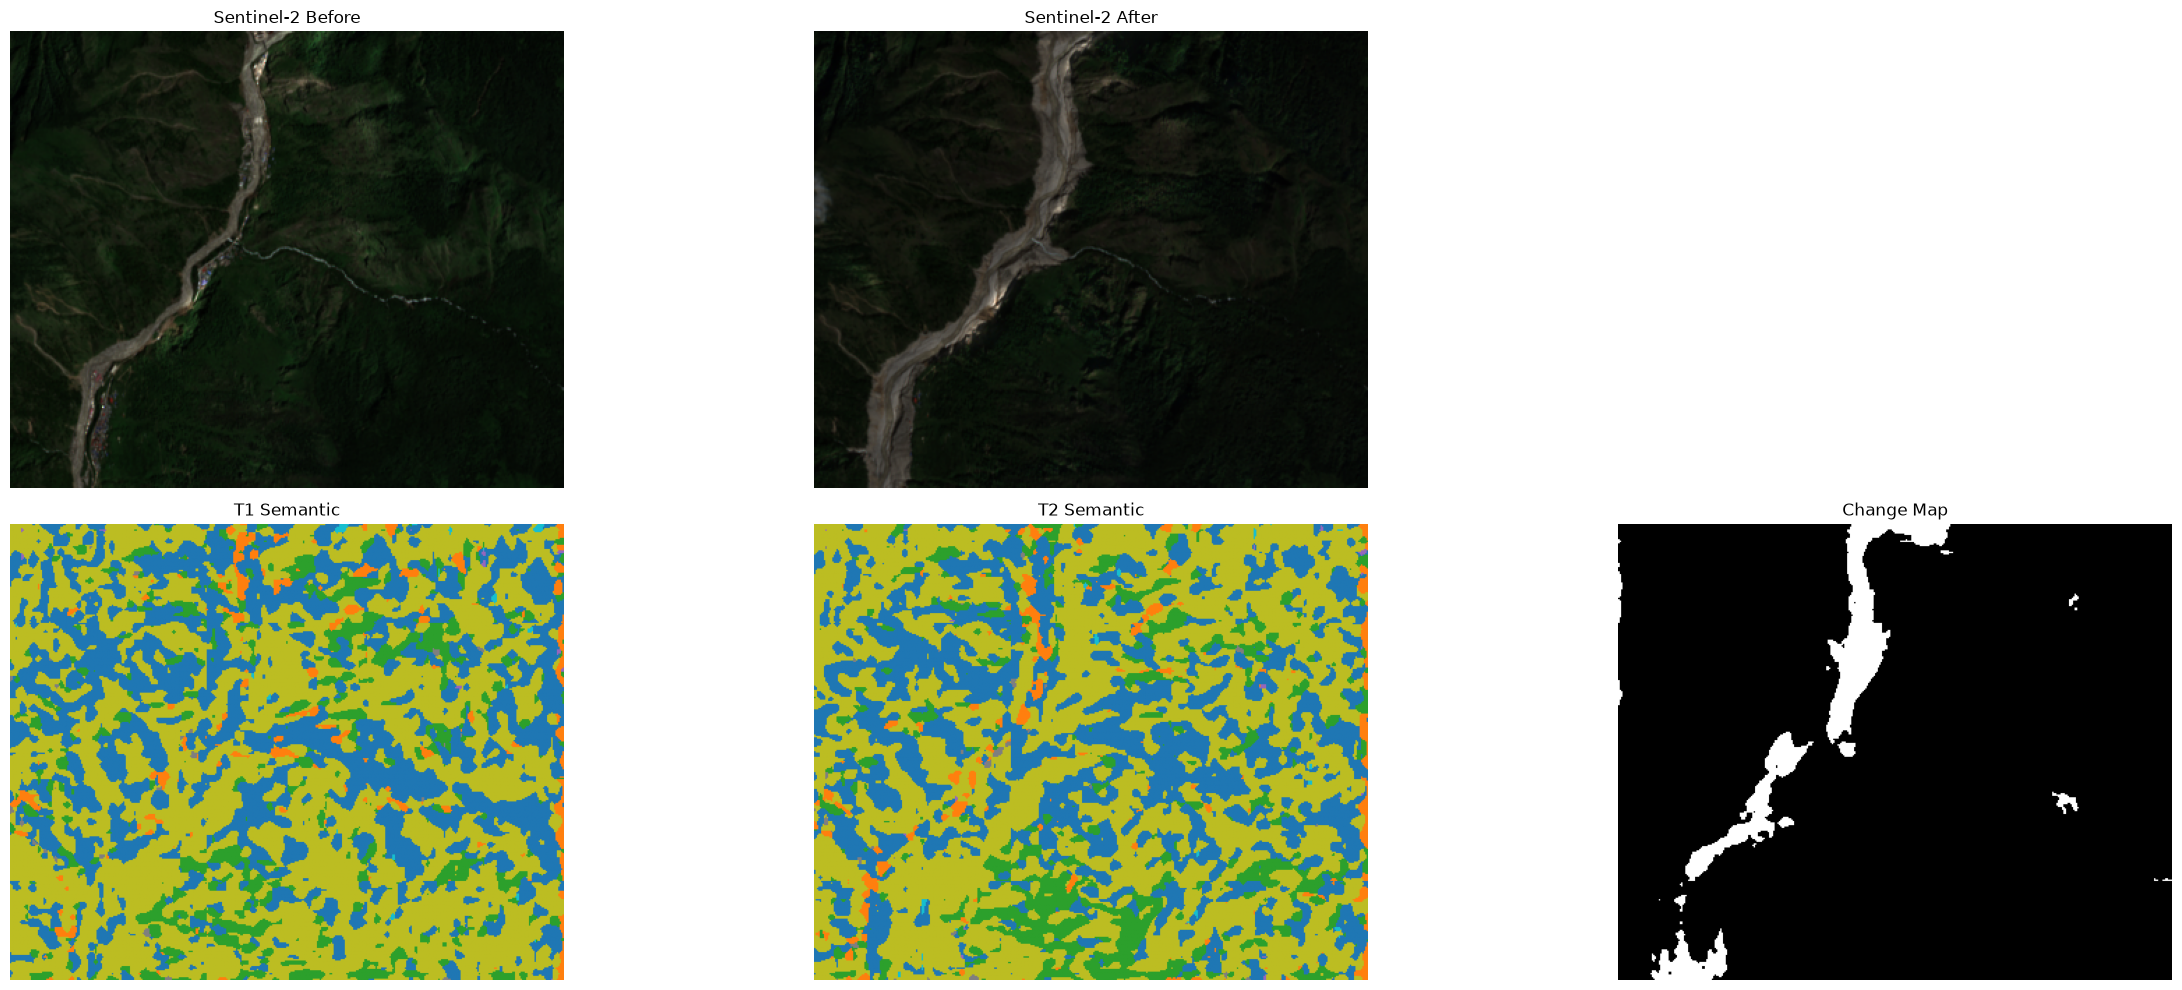

In [13]:
fig = detector_s0.visualize(
    path_before,
    path_after,
    result=result_s0,
    figsize=(25, 10),
    title1="Sentinel-2 Before",
    title2="Sentinel-2 After",
)
plt.show()

In [20]:
gt_path = PROCESSED_DATA_DIR / "s2_sub_test" / "mask" / "scene001.tif"
pred_path = MODEL_RESULTS_DIR / "change_map_s0.tif"

with rasterio.open(gt_path) as src:
    gt = src.read(1)

with rasterio.open(pred_path) as src:
    pred = src.read(1)

if gt.shape != pred.shape:
    raise ValueError(f"Shape mismatch: GT {gt.shape} vs prediction {pred.shape}")

y_true = gt > 0
y_pred = pred > 0

tp = np.count_nonzero(y_true & y_pred)
fp = np.count_nonzero(~y_true & y_pred)
fn = np.count_nonzero(y_true & ~y_pred)
tn = np.count_nonzero(~y_true & ~y_pred)

precision = tp / (tp + fp) if (tp + fp) else 0.0
recall = tp / (tp + fn) if (tp + fn) else 0.0
iou = tp / (tp + fp + fn) if (tp + fp + fn) else 0.0

print("Confusion matrix (rows = actual, columns = predicted)")
print(f"{'':>18}{'Pred 0':>12}{'Pred 1':>12}")
print(f"{'Actual 0':>18}{tn:>12}{fp:>12}")
print(f"{'Actual 1':>18}{fn:>12}{tp:>12}")
print()
print(f"Precision: {precision:.3f}")
print(f"Recall:    {recall:.3f}")
print(f"IoU:       {iou:.3f}")


Confusion matrix (rows = actual, columns = predicted)
                        Pred 0      Pred 1
          Actual 0      116799        2144
          Actual 1        5944        4932

Precision: 0.697
Recall:    0.453
IoU:       0.379


GT shape: (327, 397) dtype: uint8 nodata: 0.0
GT unique values: (array([0, 1], dtype=uint8), array([118943,  10876]))
GT CRS: EPSG:32645 bounds: BoundingBox(left=339112.52624086034, bottom=3125988.266408861, right=343082.52624086034, top=3129258.266408861)
Pred shape: (327, 397) dtype: uint8 nodata: None
Pred unique values (first 10): [0 1]
Pred CRS: EPSG:32645 bounds: BoundingBox(left=339112.52624086034, bottom=3125988.266408861, right=343082.52624086034, top=3129258.266408861)


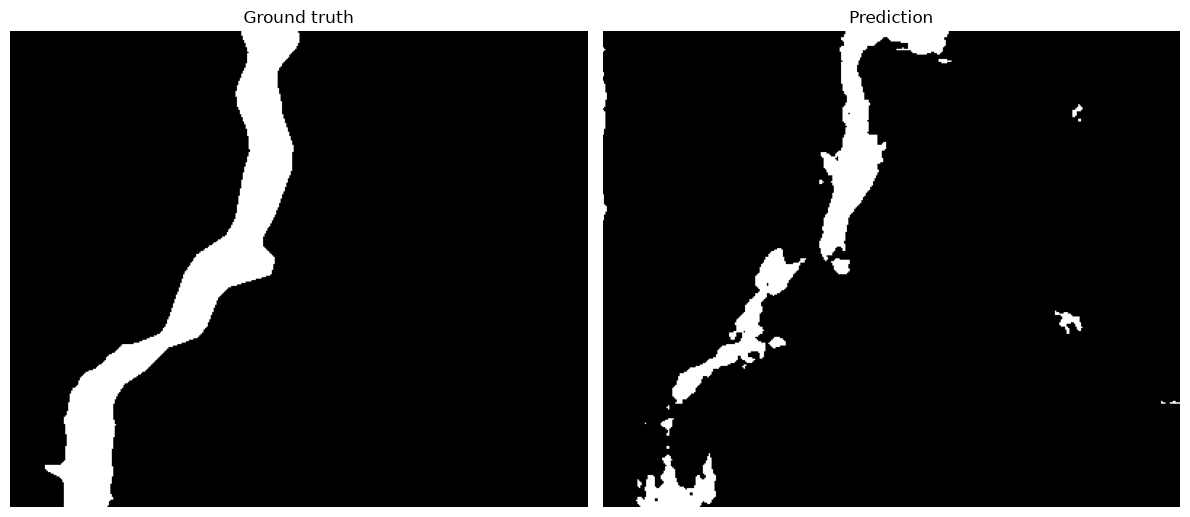

In [15]:

with rasterio.open(gt_path) as src:
    gt = src.read(1)
    print("GT shape:", gt.shape, "dtype:", gt.dtype, "nodata:", src.nodata)
    print("GT unique values:", np.unique(gt, return_counts=True))
    print("GT CRS:", src.crs, "bounds:", src.bounds)

with rasterio.open(pred_path) as src:
    pred = src.read(1)
    print("Pred shape:", pred.shape, "dtype:", pred.dtype, "nodata:", src.nodata)
    print("Pred unique values (first 10):", np.unique(pred)[:10])
    print("Pred CRS:", src.crs, "bounds:", src.bounds)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(gt, cmap="gray")
axes[0].set_title("Ground truth")
axes[1].imshow(pred, cmap="gray")
axes[1].set_title("Prediction")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()


## Change Vector Analysis

In [4]:
import numpy as np

with rasterio.open(path_before) as src:
    red_before = src.read(1).astype(np.float32)
    blue_before = src.read(2).astype(np.float32)
    green_before = src.read(3).astype(np.float32)

with rasterio.open(path_after) as src:
    red_after = src.read(1).astype(np.float32)
    blue_after = src.read(2).astype(np.float32)
    green_after = src.read(3).astype(np.float32)

delta_red = red_after - red_before
delta_blue = blue_after - blue_before
delta_green = green_after - green_before

magnitude = np.sqrt(delta_red**2 + delta_blue**2 + delta_green**2)
direction = np.degrees(np.arctan2(delta_green, delta_red)) #can't properly compute direction with 3 bands

mag_threshold = np.percentile(magnitude, 95)
significant_change = magnitude > mag_threshold

print(f"CVA magnitude range: {magnitude.min():.2f} to {magnitude.max():.2f}")
print(f"95th percentile threshold: {mag_threshold:.2f}")
print(f"Significant change pixels: {significant_change.sum():,}")

CVA magnitude range: 2.45 to 8841.64
95th percentile threshold: 1347.29
Significant change pixels: 6,491


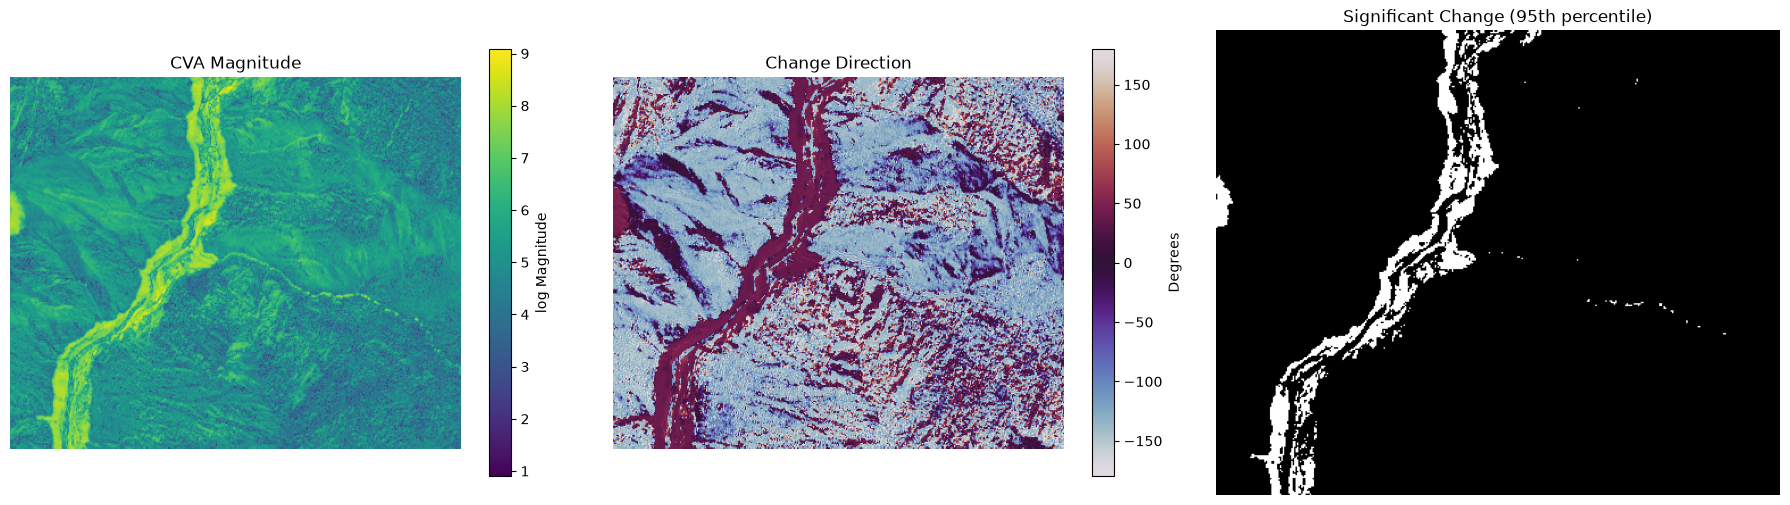

In [5]:
## plotting the results

import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# 1. Change magnitude
im0 = axes[0].imshow(np.log(magnitude), cmap="viridis")
axes[0].set_title("CVA Magnitude")
plt.colorbar(im0, ax=axes[0], shrink=0.75, label="log Magnitude")

# 2. Change direction
im1 = axes[1].imshow(direction, cmap="twilight", vmin=-180, vmax=180)
axes[1].set_title("Change Direction")
plt.colorbar(im1, ax=axes[1], shrink=0.75, label="Degrees")

# 3. Significant change
axes[2].imshow(significant_change, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("Significant Change (95th percentile)")

for ax in axes:
    ax.set_axis_off()

plt.tight_layout()
plt.show()